# Reto S07 · «Precio y cancelación» · TurisData Canarias
Ejecutar de arriba abajo (*Reiniciar y ejecutar todo*). `SEMILLA = 42`.

## Paso 1 · Datos e hipótesis de coste

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in (".", "datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

SEMILLA = 42
df = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_reserva", "fecha_llegada"])
df["mes_llegada"] = df["fecha_llegada"].dt.month
df["temporada_alta"] = df["mes_llegada"].isin([1, 2, 3, 7, 8, 12]).astype(int)
print(df.shape, "· % canceladas:", round(df["cancelada"].mean(), 3))

(6000, 20) · % canceladas: 0.459


In [2]:
precio_medio = df["precio_noche"].mean()
noches_medias = df["noches"].mean()
print(round(precio_medio, 2), "€ por noche ·", round(noches_medias, 2), "noches por reserva")
print(round(0.5 * noches_medias * precio_medio), "€ ≈ la mitad de las noches de una reserva media")

102.87 € por noche · 5.52 noches por reserva
284 € ≈ la mitad de las noches de una reserva media


In [3]:
COSTE_FN = 284   # cancelación no prevista: reserva media de 5,5 noches a ~103 €; solo se revende la mitad (0,5 × 5,52 × 102,87 ≈ 284 €)
COSTE_FP = 103   # falsa alarma: se sobrevende y hay que reubicar al cliente: una noche en otro alojamiento + disculpa ≈ precio medio de una noche

## Paso 2 · Regresión del precio
Variables conocidas al reservar: tipo de habitación y temporada. `cancelada` queda fuera (fuga).

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Xp = pd.get_dummies(df[["tipo_habitacion"]], drop_first=True).astype(int)
Xp["temporada_alta"] = df["temporada_alta"]
yp = df["precio_noche"]
assert "cancelada" not in Xp.columns and "precio_noche" not in Xp.columns
Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xp, yp, test_size=0.2, random_state=SEMILLA)
print(Xp.shape, Xp_train.shape, Xp_test.shape)

(6000, 4) (4800, 4) (1200, 4)


In [5]:
modelos = {
    "Referencia (media)": DummyRegressor(strategy="mean"),
    "Regresión lineal": LinearRegression(),
    "Lineal con interacciones": make_pipeline(PolynomialFeatures(degree=2, interaction_only=True, include_bias=False), LinearRegression()),
}
filas, preds_precio = {}, {}
for nombre, modelo in modelos.items():
    modelo.fit(Xp_train, yp_train)
    pred = modelo.predict(Xp_test)
    preds_precio[nombre] = pred
    filas[nombre] = {"MAE (€)": mean_absolute_error(yp_test, pred),
                     "RMSE (€)": mean_squared_error(yp_test, pred) ** 0.5,
                     "R²": r2_score(yp_test, pred)}
resultados_precio = pd.DataFrame(filas).T.round(3)
resultados_precio

,MAE (€),RMSE (€),R²
Referencia (media),25.564,33.328,-0.002
Regresión lineal,7.239,9.704,0.915
Lineal con interacciones,6.758,8.936,0.928


In [6]:
lineal = modelos["Regresión lineal"]
print(pd.Series(lineal.coef_, index=Xp.columns).round(1))
print("Precio base (estándar en temporada baja):", round(lineal.intercept_, 1), "€")
inter = modelos["Lineal con interacciones"]
nombres_inter = inter.named_steps["polynomialfeatures"].get_feature_names_out(Xp.columns)
print(pd.Series(inter.named_steps["linearregression"].coef_, index=nombres_inter).round(1))

tipo_habitacion_familiar     45.0
tipo_habitacion_suite       101.2
tipo_habitacion_superior     28.4
temporada_alta               22.4
dtype: float64
Precio base (estándar en temporada baja): 67.3 €
tipo_habitacion_familiar                             39.8
tipo_habitacion_suite                                91.0
tipo_habitacion_superior                             25.5
temporada_alta                                       17.5
tipo_habitacion_familiar tipo_habitacion_suite        0.0
tipo_habitacion_familiar tipo_habitacion_superior    -0.0
tipo_habitacion_familiar temporada_alta              10.1
tipo_habitacion_suite tipo_habitacion_superior        0.0
tipo_habitacion_suite temporada_alta                 19.4
tipo_habitacion_superior temporada_alta               5.9
dtype: float64


temporada_alta     0     1
tipo                      
estandar         4.2   5.8
familiar         7.3   8.1
suite           10.1  15.2
superior         6.2   8.0
% de reservas con error > 20 €: 3.3


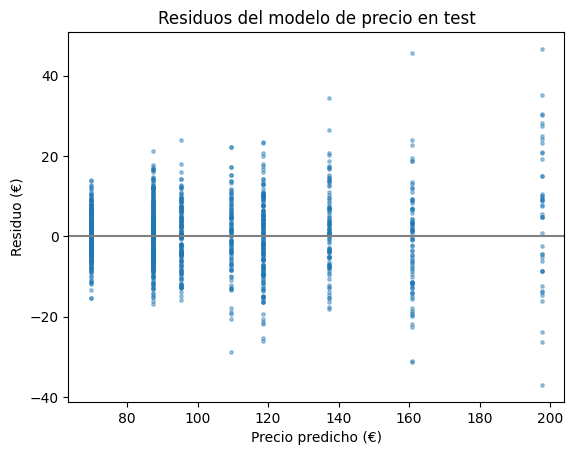

In [7]:
# Residuos: ¿dónde falla el modelo?
res = pd.DataFrame({"tipo": df.loc[yp_test.index, "tipo_habitacion"],
                    "temporada_alta": Xp_test["temporada_alta"],
                    "error": yp_test - preds_precio["Lineal con interacciones"]})
res["abs"] = res["error"].abs()
print(res.groupby(["tipo", "temporada_alta"])["abs"].mean().round(1).unstack())
print("% de reservas con error > 20 €:", round((res["abs"] > 20).mean() * 100, 1))
plt.scatter(preds_precio["Lineal con interacciones"], res["error"], s=6, alpha=0.4)
plt.axhline(0, color="gray"); plt.xlabel("Precio predicho (€)"); plt.ylabel("Residuo (€)")
plt.title("Residuos del modelo de precio en test"); plt.show()

## Paso 3 · Clasificación de la cancelación y umbral

In [8]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "temporada_alta"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X, y = df[columnas_num + columnas_cat], df["cancelada"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), columnas_num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), columnas_cat),
])
logit = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])
tonto = Pipeline([("prep", clone(prep)), ("clf", DummyClassifier(strategy="most_frequent"))])
knn = Pipeline([("prep", clone(prep)), ("clf", KNeighborsClassifier(n_neighbors=25))])
print(X_train.shape, X_test.shape, round(y_train.mean(), 3), round(y_test.mean(), 3))

(4800, 15) (1200, 15) 0.459 0.459


In [9]:
def metricas_umbral(y_real, proba, umbral):
    pred = (proba >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {"umbral": umbral, "VN": int(vn), "FP": int(fp), "FN": int(fn), "VP": int(vp),
            "precision": float(vp / (vp + fp)) if (vp + fp) else np.nan,
            "recall": float(vp / (vp + fn))}

def coste_total(y_real, proba, umbral, coste_fn, coste_fp):
    m = metricas_umbral(y_real, proba, umbral)
    return m["FN"] * coste_fn + m["FP"] * coste_fp

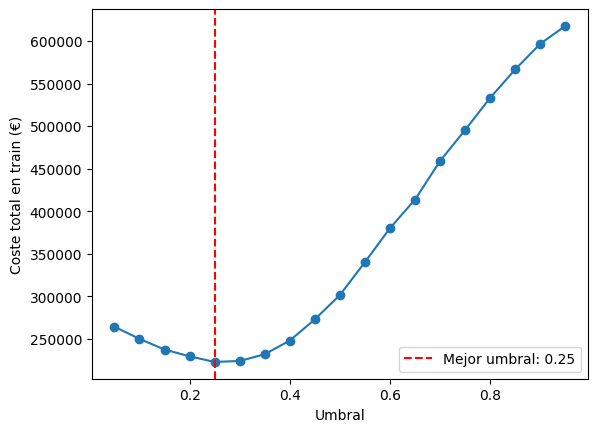

Umbral elegido (logística): 0.25 · umbral k-NN: 0.35
AUC en CV (train): logística 0.758 · k-NN 0.693


In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
proba_cv = cross_val_predict(logit, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
proba_cv_knn = cross_val_predict(knn, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
umbrales = np.arange(0.05, 0.96, 0.05)

def buscar_umbral(coste_fn, coste_fp, proba=None):
    """Prueba todos los umbrales con las probabilidades de train (CV) y devuelve el de menor coste."""
    proba = proba_cv if proba is None else proba
    costes = [coste_total(y_train, proba, u, coste_fn, coste_fp) for u in umbrales]
    return round(float(umbrales[np.argmin(costes)]), 2), costes

mejor_umbral, costes = buscar_umbral(COSTE_FN, COSTE_FP)
umbral_knn, _ = buscar_umbral(COSTE_FN, COSTE_FP, proba_cv_knn)
plt.plot(umbrales, costes, marker="o")
plt.axvline(mejor_umbral, color="red", linestyle="--", label=f"Mejor umbral: {mejor_umbral}")
plt.xlabel("Umbral"); plt.ylabel("Coste total en train (€)"); plt.legend(); plt.show()
print("Umbral elegido (logística):", mejor_umbral, "· umbral k-NN:", umbral_knn)
print("AUC en CV (train): logística", round(roc_auc_score(y_train, proba_cv), 3), "· k-NN", round(roc_auc_score(y_train, proba_cv_knn), 3))

### Test: se abre una sola vez

Coste en test sin modelo: 156,484 €
Coste en test con umbral 0.5: 78,439 €
Coste en test con umbral 0.25: 58,331 €
Coste en test k-NN (umbral 0.35): 64,008 €
Ahorro frente a no hacer nada: 98,153 € (63%)
           modelo    AUC     AP  recall  precision   FN   FP  coste_€
0      Referencia  0.500  0.459   0.000        NaN  551    0   156484
1   Logística 0,5  0.746  0.729   0.615      0.657  212  177    78439
2  Logística 0.25  0.746  0.729   0.920      0.533   44  445    58331
3       k-NN 0.35  0.697  0.657   0.891      0.518   60  456    64008
VN 204 · FP 445 · FN 44 · VP 507


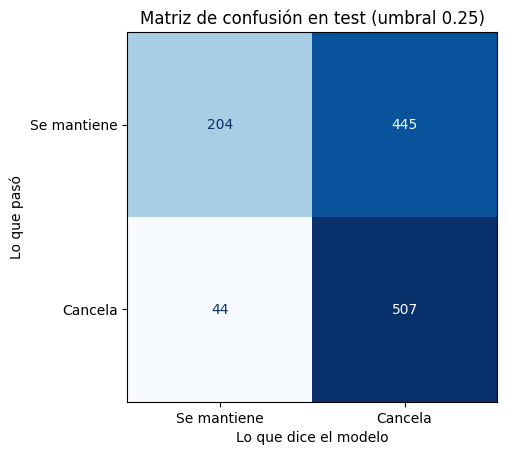

In [11]:
logit.fit(X_train, y_train); tonto.fit(X_train, y_train); knn.fit(X_train, y_train)
proba_test = logit.predict_proba(X_test)[:, 1]
proba_tonto = tonto.predict_proba(X_test)[:, 1]
proba_knn = knn.predict_proba(X_test)[:, 1]

coste_sin_modelo = y_test.sum() * COSTE_FN
coste_05 = coste_total(y_test, proba_test, 0.5, COSTE_FN, COSTE_FP)
coste_elegido = coste_total(y_test, proba_test, mejor_umbral, COSTE_FN, COSTE_FP)
coste_knn = coste_total(y_test, proba_knn, umbral_knn, COSTE_FN, COSTE_FP)
print("Coste en test sin modelo: {:,.0f} €".format(coste_sin_modelo))
print("Coste en test con umbral 0.5: {:,.0f} €".format(coste_05))
print("Coste en test con umbral {}: {:,.0f} €".format(mejor_umbral, coste_elegido))
print("Coste en test k-NN (umbral {}): {:,.0f} €".format(umbral_knn, coste_knn))
ahorro = coste_sin_modelo - coste_elegido
print("Ahorro frente a no hacer nada: {:,.0f} € ({:.0%})".format(ahorro, ahorro / coste_sin_modelo))

tabla = []
for nombre, p, u in [("Referencia", proba_tonto, 0.5), ("Logística 0,5", proba_test, 0.5),
                     (f"Logística {mejor_umbral}", proba_test, mejor_umbral), (f"k-NN {umbral_knn}", proba_knn, umbral_knn)]:
    m = metricas_umbral(y_test, p, u)
    tabla.append({"modelo": nombre, "AUC": roc_auc_score(y_test, p), "AP": average_precision_score(y_test, p),
                  "recall": m["recall"], "precision": m["precision"], "FN": m["FN"], "FP": m["FP"],
                  "coste_€": coste_total(y_test, p, u, COSTE_FN, COSTE_FP)})
resultados_cancel = pd.DataFrame(tabla).round(3)
print(resultados_cancel)

m = metricas_umbral(y_test, proba_test, mejor_umbral)
print("VN {VN} · FP {FP} · FN {FN} · VP {VP}".format(**m))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= mejor_umbral).astype(int),
                                        display_labels=["Se mantiene", "Cancela"], cmap="Blues", colorbar=False)
plt.title(f"Matriz de confusión en test (umbral {mejor_umbral})")
plt.xlabel("Lo que dice el modelo"); plt.ylabel("Lo que pasó"); plt.show()

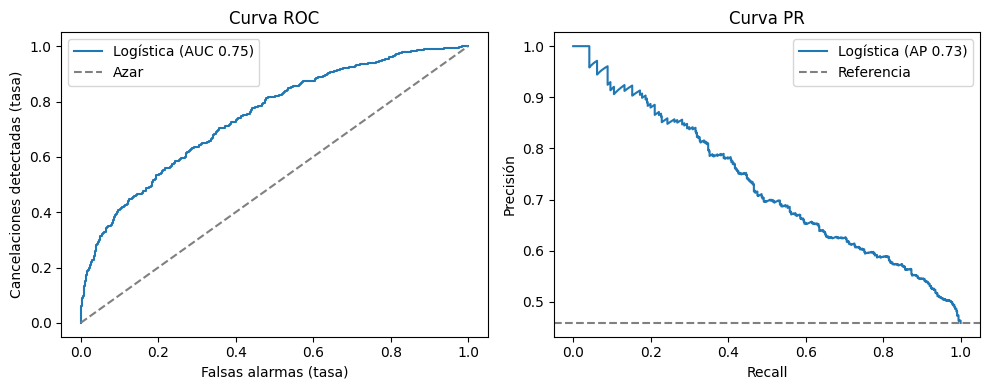

In [12]:
fpr, tpr, _ = roc_curve(y_test, proba_test)
prec, rec, _ = precision_recall_curve(y_test, proba_test)
auc, ap = roc_auc_score(y_test, proba_test), average_precision_score(y_test, proba_test)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].plot(fpr, tpr, label=f"Logística (AUC {auc:.2f})")
ejes[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar")
ejes[0].set(title="Curva ROC", xlabel="Falsas alarmas (tasa)", ylabel="Cancelaciones detectadas (tasa)")
ejes[1].plot(rec, prec, label=f"Logística (AP {ap:.2f})")
ejes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Referencia")
ejes[1].set(title="Curva PR", xlabel="Recall", ylabel="Precisión")
ejes[0].legend(); ejes[1].legend(); plt.tight_layout(); plt.show()

In [13]:
# Odds ratios (numéricas: por cada desviación típica; categóricas: frente a la categoría de referencia/ausencia)
nombres = logit.named_steps["prep"].get_feature_names_out()
odds = pd.Series(np.exp(logit.named_steps["clf"].coef_[0]), index=nombres).sort_values()
print("Más reducen el riesgo:\n", odds.head(6).round(2))
print("Más aumentan el riesgo:\n", odds.tail(6).round(2))
print("Desv. típicas:", X_train[["antelacion_dias", "cancelaciones_previas", "peticiones_especiales"]].std().round(1).to_dict())

Más reducen el riesgo:
 cat__tarifa_no_reembolsable      0.44
cat__deposito_total              0.46
cat__canal_directo               0.55
num__precio_noche                0.62
cat__tipo_habitacion_estandar    0.73
cat__pais_origen_NL              0.82
dtype: float64
Más aumentan el riesgo:
 cat__pais_origen_FR             1.15
num__temporada_alta             1.33
cat__tipo_habitacion_suite      1.47
cat__canal_web_intermediaria    1.70
cat__deposito_sin_deposito      2.00
num__antelacion_dias            2.12
dtype: float64
Desv. típicas: {'antelacion_dias': 62.1, 'cancelaciones_previas': 0.3, 'peticiones_especiales': 0.8}


## Paso 4 · Análisis de sensibilidad (sobre train, con CV)

In [14]:
hipotesis = [("la nuestra", COSTE_FN, COSTE_FP),
             ("FN el doble", COSTE_FN * 2, COSTE_FP),
             ("FN la mitad", COSTE_FN / 2, COSTE_FP),
             ("FP la mitad", COSTE_FN, COSTE_FP / 2),
             ("FP el doble", COSTE_FN, COSTE_FP * 2)]
filas = []
for nombre, coste_fn, coste_fp in hipotesis:
    umbral, cst = buscar_umbral(coste_fn, coste_fp)
    filas.append({"hipótesis": nombre, "COSTE_FN": coste_fn, "COSTE_FP": coste_fp,
                  "umbral_optimo": umbral, "coste_total": round(min(cst)),
                  "sin_modelo": round(y_train.sum() * coste_fn),
                  "coste_si_mantengo_nuestro_umbral": round(coste_total(y_train, proba_cv, mejor_umbral, coste_fn, coste_fp))})
sensibilidad = pd.DataFrame(filas)
sensibilidad["ahorro_%"] = (1 - sensibilidad["coste_total"] / sensibilidad["sin_modelo"]).round(3) * 100
print(sensibilidad.to_string())

     hipótesis  COSTE_FN  COSTE_FP  umbral_optimo  coste_total  sin_modelo  coste_si_mantengo_nuestro_umbral  ahorro_%
0   la nuestra     284.0     103.0           0.25       223121      625652                            223121      64.3
1  FN el doble     568.0     103.0           0.15       249011     1251304                            270833      80.1
2  FN la mitad     142.0     103.0           0.40       177360      312826                            199265      43.3
3  FP la mitad     284.0      51.5           0.15       124506      625652                            135416      80.1
4  FP el doble     284.0     206.0           0.40       354720      625652                            398530      43.3


## IA responsable: ¿a quién le tocan las falsas alarmas?

In [15]:
resultado = X_test.copy()
resultado["real"] = y_test
resultado["aviso"] = (proba_test >= mejor_umbral).astype(int)
no_canceladas = resultado[resultado["real"] == 0]
for col in ["canal", "pais_origen", "deposito"]:
    print(no_canceladas.groupby(col)["aviso"].agg(["mean", "size"]).round(2), "\n")

                   mean  size
canal                        
agencia            0.65   136
directo            0.49   207
empresa            0.74    38
web_intermediaria  0.85   268 

             mean  size
pais_origen            
DE           0.66    83
ES           0.70   168
FR           0.66    29
IT           0.69    36
NL           0.59    32
Nordicos     0.71    45
UK           0.70   162
otros        0.68    74 

              mean  size
deposito                
parcial       0.61   202
sin_deposito  0.86   324
total         0.34   123 



## Versiones

In [16]:
import sys, sklearn, matplotlib
print("Python", sys.version.split()[0], "· pandas", pd.__version__, "· numpy", np.__version__,
      "· scikit-learn", sklearn.__version__, "· matplotlib", matplotlib.__version__)

Python 3.13.18 · pandas 2.2.3 · numpy 2.4.6 · scikit-learn 1.6.1 · matplotlib 3.10.0
